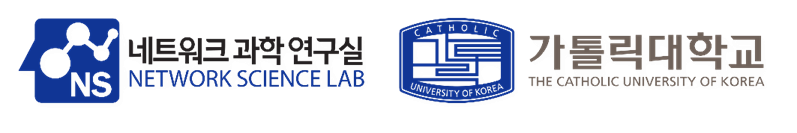

# Solution 6: GNNs under Heterophily

## Setup

In [1]:
import math, time, random, copy, warnings, contextlib, io
warnings.filterwarnings("ignore")                # optional-extension notices of PyG / tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.datasets import Planetoid, WebKB, WikipediaNetwork, Actor
from torch_geometric.utils import to_dense_adj

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(0)
HOMO_COLOR, HETERO_COLOR = "#2a78d6", "#eb6834"

Device: cpu


In [2]:
def sym_norm(A, self_loops=True):
    """Symmetric normalisation  D^{-1/2} (A [+ I]) D^{-1/2}  of a dense (possibly weighted) adjacency."""
    if self_loops:
        A = A + torch.eye(A.size(0), device=A.device)
    d_inv_sqrt = A.sum(1).pow(-0.5)
    d_inv_sqrt[torch.isinf(d_inv_sqrt)] = 0.
    return d_inv_sqrt[:, None] * A * d_inv_sqrt[None, :]

def row_norm(A):
    """Random-walk normalisation  D^{-1} A  (mean over neighbours)."""
    return A / A.sum(1, keepdim=True).clamp(min=1e-12)

def two_hop(A):
    """Exact 2-hop neighbourhood: reachable in two steps, but not in one step and not the node itself."""
    A2 = ((A @ A) > 0).float()
    A2 = A2 * (1 - A)
    A2.fill_diagonal_(0)
    return A2

def input_dropout(x, p, training):
    """Dropout on the (sparse, bag-of-words) input features. Zero entries stay zero under dropout anyway, so we only
    draw random numbers for the non-zero entries: same result as F.dropout, but much faster on large inputs."""
    if not training or p == 0:
        return x
    idx = x.nonzero(as_tuple=True)
    keep = (torch.rand(idx[0].numel(), device=x.device) >= p).float() / (1 - p)
    out = torch.zeros_like(x)
    out[idx] = x[idx] * keep
    return out

def edges_of(A):
    """Directed edge list (both directions) of a dense adjacency: rows i (receivers) and columns j (senders)."""
    return A.nonzero(as_tuple=True)

def as_operator(M, max_density=0.05):
    """Store a fixed propagation matrix as a torch sparse tensor when it is sparse enough (much faster  M @ h  on
    large graphs); keep it dense otherwise. The models only use it as  M @ h, so both formats work."""
    return M.to_sparse() if (M != 0).float().mean().item() < max_density else M

def edge_matmul(rows, cols, values, h):
    """out_i = Σ_j w_ij h_j  for edge weights `values` on the edges (rows, cols): a sparse matrix product
    that is differentiable with respect to the edge weights (used by the attention / signed-edge models)."""
    W = torch.sparse_coo_tensor(torch.stack([rows, cols]), values, (h.size(0), h.size(0)))
    return torch.sparse.mm(W, h)

def edge_softmax(scores, rows, N):
    """Softmax of the edge scores over the edges of each receiving node i (its neighbourhood)."""
    m = torch.full((N,), -float('inf'), device=scores.device).scatter_reduce(0, rows, scores.detach(), 'amax')
    e = (scores - m[rows]).exp()
    return e / torch.zeros(N, device=scores.device).index_add_(0, rows, e)[rows]

def cosine_sim(Z):
    Zn = F.normalize(Z, dim=1)
    return Zn @ Zn.t()

def knn_graph(Z, k):
    """Symmetric k-nearest-neighbour graph under cosine similarity (no self-loops)."""
    S = cosine_sim(Z)
    S.fill_diagonal_(-float('inf'))
    idx = S.topk(k, dim=1).indices
    G = torch.zeros_like(S).scatter_(1, idx, 1.)
    return ((G + G.t()) > 0).float()

In [3]:
ROOT = "./data"

class Graph:
    """Dense tensors of one node-classification dataset and its 10 standard (Geom-GCN) splits."""
    def __init__(self, name):
        with contextlib.redirect_stderr(io.StringIO()):                  # hide PyG's download log
            if name in ("Cora", "CiteSeer", "PubMed"):
                ds = Planetoid(ROOT, name, split="geom-gcn")
            elif name in ("Texas", "Wisconsin", "Cornell"):
                ds = WebKB(ROOT, name)
            elif name in ("Chameleon", "Squirrel"):
                ds = WikipediaNetwork(ROOT, name.lower())
            elif name == "Actor":
                ds = Actor(f"{ROOT}/Actor")
        data = ds[0]
        self.name, self.N = name, data.num_nodes
        self.C = int(data.y.max()) + 1
        X = data.x.float()
        self.X = (X / X.sum(1, keepdim=True).clamp(min=1)).to(device)   # row-normalised features
        self.F = X.size(1)
        self.y = data.y.to(device)
        A = to_dense_adj(data.edge_index, max_num_nodes=self.N)[0]
        A = ((A + A.t()) > 0).float()                                    # undirected, binary
        A.fill_diagonal_(0)                                              # no self-loops
        self.A = A.to(device)
        self.A_hat = sym_norm(self.A)                                    # GCN propagation matrix
        self.masks = [m.to(device) for m in (data.train_mask, data.val_mask, data.test_mask)]

    def split(self, i):
        """(train, val, test) boolean masks of split i (60/20/20 for WebKB / Wikipedia, Geom-GCN splits for Cora)."""
        return tuple(m[:, i] for m in self.masks)

    def __repr__(self):
        return (f"{self.name}: {self.N} nodes, {int(self.A.sum().item()) // 2} edges, "
                f"{self.F} features, {self.C} classes")

In [4]:
def accuracy(pred_y, y):
    return (pred_y == y).float().mean().item()

def train_model(model, g, split, epochs=300, lr=0.01, weight_decay=5e-4, patience=100,
                verbose=False, log_every=50):
    """Full-batch training on split `split` with early stopping on validation accuracy.
    The model is called as model(g.X); models that need a graph store their own operators.
    If the model defines reg_loss(), it is added to the cross-entropy (e.g. graph-structure-learning regularisers).
    Returns (best validation accuracy, test accuracy at that epoch)."""
    tr, va, te = g.split(split)
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val, best_val_loss, best_test, bad, best_state = -1., float('inf'), 0., 0, None
    for epoch in range(1, epochs + 1):
        model.train()
        opt.zero_grad()
        out = model(g.X)
        loss = F.cross_entropy(out[tr], g.y[tr])
        if hasattr(model, 'reg_loss'):
            loss = loss + model.reg_loss()
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            out = model(g.X)
            val_loss = F.cross_entropy(out[va], g.y[va]).item()
            pred = out.argmax(1)
            train_acc, val_acc, test_acc = (accuracy(pred[m], g.y[m]) for m in (tr, va, te))
        if val_acc > best_val or (val_acc == best_val and val_loss < best_val_loss):
            best_val, best_val_loss, best_test, bad = val_acc, val_loss, test_acc, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
        if verbose and (epoch == 1 or epoch % log_every == 0):
            print(f'Epoch {epoch:>3} | Train Loss: {loss.item():.3f} | Train Acc: {train_acc*100:6.2f}% | '
                  f'Val Loss: {val_loss:.3f} | Val Acc: {val_acc*100:6.2f}%')
        if bad >= patience:
            break
    model.load_state_dict(best_state)
    if verbose:
        print(f'>> Val Acc: {best_val*100:.2f}% | Test Acc: {best_test*100:.2f}%')
    return best_val, best_test

RESULTS = {}

def benchmark(name, make_model, graphs, splits=(0, 1, 2), **train_kwargs):
    """Train make_model(g, split) on every graph and split; store and print the mean ± std test accuracy."""
    row = []
    for g in graphs:
        accs = []
        for s in splits:
            set_seed(s)
            _, test_acc = train_model(make_model(g, s), g, s, **train_kwargs)
            accs.append(test_acc)
        RESULTS[(name, g.name)] = np.array(accs)
        row.append(f'{g.name}: {np.mean(accs)*100:5.1f} ± {np.std(accs)*100:4.1f}')
    print(f'{name:<10} | ' + ' | '.join(row))

def results_table(models=None, datasets=None):
    models = models or list(dict.fromkeys(m for m, _ in RESULTS))
    datasets = datasets or list(dict.fromkeys(d for _, d in RESULTS))
    return pd.DataFrame({d: [f"{RESULTS[(m, d)].mean()*100:.1f} ± {RESULTS[(m, d)].std()*100:.1f}"
                             if (m, d) in RESULTS else "" for m in models] for d in datasets}, index=models)

SPLITS = (0, 1, 2)
HIDDEN = 64

def benchmark_once(name, make_model, graphs, splits=SPLITS, **kw):
    """benchmark() that skips the (model, dataset) pairs that were already trained earlier in this notebook."""
    todo = [g for g in graphs if (name, g.name) not in RESULTS]
    if todo:
        benchmark(name, make_model, todo, splits, **kw)

# Assignment 1. Measuring heterophily.

Questions:

1) Load Cora, CiteSeer, Texas, Wisconsin, Cornell, Chameleon, Squirrel and Actor from Torch Geometric. Show some statistics of each graph: number of nodes, edges, features and classes, mean degree and number of isolated nodes.
2) Implement the edge, node, class and adjusted homophily and the label informativeness $LI = I(y_u;y_v)/H(y_u)$ (slides 12–16). Report the five metrics of the eight datasets in one table and compare your $h_{edge}$ and $h_{node}$.
3) Implement the Classifier-based Performance Metric (CPM) (slides 10–11): sample 500 nodes, split them 60/40, train a Gaussian Naive Bayes classifier on $X$ and on $H = \hat A X$, repeat 100 times, and compute the p-value of $H_0: \text{Acc}(H) \ge \text{Acc}(X)$. Which datasets show malignant heterophily? Compare with the categories (malignant / benign / ambiguous).
4) Build the two toy graphs: (a) a bipartite graph with 2 classes (every edge joins the two classes) and (b) a 4-class graph in which every node links to nodes of random other classes. Both have $h_{edge} = 0$. Report their label informativeness and the accuracy of a logistic regression trained on $X$ and on $D^{-1}AX$, and explain the difference between good and bad heterophily.

### 1) Graph statistics

In [5]:
NAMES = ["Cora", "CiteSeer", "Texas", "Wisconsin", "Cornell", "Chameleon", "Squirrel", "Actor"]
all_graphs = {name: Graph(name) for name in NAMES}

stats_rows = {}
for name, g in all_graphs.items():
    deg = g.A.sum(1)
    stats_rows[name] = {'nodes': g.N, 'edges': int(g.A.sum().item()) // 2, 'features': g.F, 'classes': g.C,
                        'mean degree': round(deg.mean().item(), 2), 'isolated nodes': int((deg == 0).sum())}
pd.DataFrame(stats_rows).T

,nodes,edges,features,classes,mean degree,isolated nodes
Cora,2708.0,5278.0,1433.0,7.0,3.90,0.0
CiteSeer,3327.0,4552.0,3703.0,6.0,2.74,48.0
Texas,183.0,279.0,1703.0,5.0,3.05,0.0
Wisconsin,251.0,450.0,1703.0,5.0,3.59,0.0
Cornell,183.0,277.0,1703.0,5.0,3.03,0.0
Chameleon,2277.0,31371.0,2325.0,5.0,27.55,0.0
Squirrel,5201.0,198353.0,2089.0,5.0,76.27,0.0
Actor,7600.0,26659.0,932.0,5.0,7.02,0.0


### 2) Homophily metrics

In [6]:
def edge_homophily(A, y):
    """Fraction of edges that join two nodes of the same class."""
    src, dst = edges_of(A)
    return (y[src] == y[dst]).float().mean().item()

def node_homophily(A, y):
    """Per-node fraction of same-class neighbours, averaged over nodes with at least one neighbour."""
    same = (y[:, None] == y[None, :]).float()
    deg = A.sum(1)
    h = (A * same).sum(1)[deg > 0] / deg[deg > 0]
    return h.mean().item()

def local_homophily(A, y):
    """Vector of per-node homophily values (NaN for isolated nodes)."""
    same = (y[:, None] == y[None, :]).float()
    deg = A.sum(1)
    return ((A * same).sum(1) / deg).cpu().numpy()

def class_homophily(A, y):
    """Class-insensitive homophily (Lim et al., 2021): per-class homophily minus the class prior."""
    C = int(y.max()) + 1
    src, dst = edges_of(A)
    total = 0.
    for k in range(C):
        from_k = y[src] == k
        if from_k.any():
            h_k = (y[dst][from_k] == k).float().mean().item()
            total += max(0., h_k - (y == k).float().mean().item())
    return total / (C - 1)

def adjusted_homophily(A, y):
    """Edge homophily corrected for chance (Platonov et al., 2023); 0 = random wiring, < 0 = heterophily."""
    C = int(y.max()) + 1
    deg = A.sum(1)
    p = torch.zeros(C, device=A.device).index_add_(0, y, deg) / deg.sum()
    chance = (p ** 2).sum().item()
    return (edge_homophily(A, y) - chance) / (1 - chance)

def compatibility_matrix(A, y):
    """H[k, l] = fraction of edges leaving class k that land in class l."""
    C = int(y.max()) + 1
    Y = F.one_hot(y, C).float()
    H = Y.t() @ A @ Y
    return (H / H.sum(1, keepdim=True).clamp(min=1)).cpu().numpy()

def label_informativeness(A, y):
    """LI = I(y_u; y_v) / H(y_u) over edges (Platonov et al., 2023): how much a neighbour's label tells
    about the node's label, whatever the sign of the relation (1 = fully informative, 0 = useless)."""
    C = int(y.max()) + 1
    Y = F.one_hot(y, C).float()
    P = Y.t() @ A @ Y
    P = P / P.sum()                                 # joint distribution p(c1, c2) of the labels at an edge
    p = P.sum(1)                                    # marginal (degree-weighted class distribution)
    H_joint = -(P[P > 0] * P[P > 0].log()).sum()
    H_marg = -(p[p > 0] * p[p > 0].log()).sum()
    return (2 - H_joint / H_marg).item()            # (2 H(p) - H(P)) / H(p)

In [7]:
# (h_edge, h_node) reported on slides 23–24
SLIDES = {"Cora": (0.8100, 0.8252), "CiteSeer": (0.7355, 0.7062), "Texas": (0.0615, 0.0555),
          "Wisconsin": (0.1703, 0.0991), "Cornell": (0.2983, 0.2001), "Chameleon": (0.2339, 0.2467),
          "Squirrel": (0.2234, 0.2154), "Actor": (0.2163, 0.2023)}
metric_fns = {'h_edge': edge_homophily, 'h_node': node_homophily, 'h_class': class_homophily,
              'h_adj': adjusted_homophily, 'LI': label_informativeness}
homophily_table = pd.DataFrame({name: {**{m: f(g.A, g.y) for m, f in metric_fns.items()},
                                       'h_edge (slide)': SLIDES[name][0], 'h_node (slide)': SLIDES[name][1]}
                                for name, g in all_graphs.items()}).T
homophily_table.round(3)

,h_edge,h_node,h_class,h_adj,LI,h_edge (slide),h_node (slide)
Cora,0.810,0.825,0.766,0.771,0.590,0.810,0.825
CiteSeer,0.736,0.717,0.627,0.671,0.451,0.736,0.706
Texas,0.061,0.057,0.000,-0.294,0.192,0.062,0.056
Wisconsin,0.178,0.155,0.046,-0.173,0.131,0.170,0.099
Cornell,0.123,0.111,0.038,-0.220,0.156,0.298,0.200
Chameleon,0.230,0.247,0.041,0.032,0.048,0.234,0.247
Squirrel,0.222,0.217,0.031,0.007,0.001,0.223,0.215
Actor,0.217,0.220,0.006,0.003,0.000,0.216,0.202


* The values match the slides for Cora, CiteSeer, Texas, Chameleon, Squirrel and Actor (differences ≤ 0.02). The differences on Wisconsin and especially Cornell ($h_{edge}$ 0.12 vs. 0.30) come from the preprocessing: making the graphs undirected and remove self-loops and duplicate edges, while the slides use the original (directed) WebKB edge lists.
* Edge vs. node homophily are close on all eight undirected graphs; both are dominated by the large classes.
* Class / adjusted homophily remove the effect of class imbalance: Texas, Wisconsin and Cornell are clearly negative in $h_{adj}$ (fewer intra-class edges than chance), Chameleon, Squirrel and Actor are ≈ 0.
* LI separates graphs that $h_{edge}$ cannot: the WebKB graphs have a low $h_{edge}$ but a non-zero $LI$ (0.13–0.19: a neighbour's class is informative, it just predicts a *different* class), while on Squirrel and Actor $LI \approx 0$ and on Chameleon $LI = 0.05$: a neighbour's label tells almost nothing, although the three graphs have the same $h_{edge} \approx 0.22$.

### 3) Classifier-based Performance Metric (CPM)

In [8]:
from sklearn.naive_bayes import GaussianNB
from scipy import stats

def cpm(g, n_samples=500, reps=100, seed=0):
    """CPM: GNB accuracy on X vs. on ÂX over `reps` random samples, one-sided t-test of H0: Acc(ÂX) ≥ Acc(X)."""
    rng = np.random.default_rng(seed)
    X, H, y = g.X.cpu().numpy(), (g.A_hat @ g.X).cpu().numpy(), g.y.cpu().numpy()
    acc_X, acc_H = [], []
    for _ in range(reps):
        idx = rng.choice(g.N, size=min(n_samples, g.N), replace=False)
        cut = int(0.6 * len(idx))
        tr, te = idx[:cut], idx[cut:]
        acc_X.append(GaussianNB().fit(X[tr], y[tr]).score(X[te], y[te]))
        acc_H.append(GaussianNB().fit(H[tr], y[tr]).score(H[te], y[te]))
    return np.mean(acc_X), np.mean(acc_H), stats.ttest_ind(acc_H, acc_X, alternative='less').pvalue

CATEGORY = {"Cora": "homophilous", "CiteSeer": "homophilous", "Texas": "malignant", "Wisconsin": "malignant",
            "Cornell": "malignant", "Actor": "malignant", "Chameleon": "benign", "Squirrel": "benign"}
cpm_rows = {}
for name, g in all_graphs.items():
    acc_x, acc_h, p = cpm(g)
    cpm_rows[name] = {'GNB acc on X': acc_x, 'GNB acc on ÂX': acc_h, 'p-value': p,
                      'CPM verdict': 'malignant (aggregation hurts)' if p < 0.05 else 'aggregation does not hurt',
                      'slide 24': CATEGORY[name]}
pd.DataFrame(cpm_rows).T

,GNB acc on X,GNB acc on ÂX,p-value,CPM verdict,slide 24
Cora,0.4726,0.6091,1.0,aggregation does not hurt,homophilous
CiteSeer,0.5017,0.56215,1.0,aggregation does not hurt,homophilous
Texas,0.669865,0.207973,0.0,malignant (aggregation hurts),malignant
Wisconsin,0.684851,0.294851,0.0,malignant (aggregation hurts),malignant
Cornell,0.626622,0.256351,0.0,malignant (aggregation hurts),malignant
Chameleon,0.4043,0.45805,1.0,aggregation does not hurt,benign
Squirrel,0.2688,0.28185,0.996386,aggregation does not hurt,benign
Actor,0.3048,0.23345,0.0,malignant (aggregation hurts),malignant


* On the WebKB graphs (Texas, Wisconsin, Cornell) and on Actor, aggregation makes the GNB significantly worse (p ≈ 0): malignant heterophily.
* On Chameleon and Squirrel the aggregated features are not worse than the raw ones (p ≈ 1; on Chameleon they are clearly better), although their $h_{edge}$ is as low as Actor's: this is benign heterophily, and it is the reason why a GCN still beats an MLP on Chameleon.
* On the homophilous Cora and CiteSeer aggregation helps a lot, as expected.

CPM agrees with the categories of the slides, and unlike $h_{edge}$ it uses the features: it directly measures whether aggregation makes the classes more or less separable.

In [9]:
del all_graphs                                   # free the memory of the large dense graphs

### 4) Good vs. bad heterophily

In [10]:
from sklearn.linear_model import LogisticRegression

def synthetic_heterophily(kind, n=800, deg=6, dim=16, noise=2.5, seed=0):
    """'good': bipartite 2-class graph; 'bad': 4 classes, every node links to nodes of random other classes."""
    rng = np.random.default_rng(seed)
    C = 2 if kind == 'good' else 4
    y = rng.integers(0, C, n)
    means = rng.normal(0, 1, (C, dim))
    X = means[y] + noise * rng.normal(0, 1, (n, dim))
    A = np.zeros((n, n))
    for v in range(n):
        if kind == 'good':
            nb = rng.choice(np.flatnonzero(y == 1 - y[v]), size=deg // 2, replace=False)
        else:
            other_classes = rng.choice([c for c in range(C) if c != y[v]], size=deg // 2)
            nb = np.array([rng.choice(np.flatnonzero(y == c)) for c in other_classes])
        A[v, nb] = A[nb, v] = 1
    return (torch.tensor(A, dtype=torch.float, device=device), torch.tensor(X, dtype=torch.float, device=device),
            torch.tensor(y, device=device))

def linear_probe(Z, y, seed=0):
    idx = np.random.default_rng(seed).permutation(len(y))
    tr, te = idx[:len(y) // 2], idx[len(y) // 2:]
    return LogisticRegression(max_iter=2000).fit(Z[tr], y[tr]).score(Z[te], y[te])

rows = {}
for kind in ('good', 'bad'):
    A_s, X_s, y_s = synthetic_heterophily(kind)
    X_np, y_np = X_s.cpu().numpy(), y_s.cpu().numpy()
    agg = (row_norm(A_s) @ X_s).cpu().numpy()
    rows[kind] = {'h_edge': edge_homophily(A_s, y_s), 'h_adj': adjusted_homophily(A_s, y_s),
                  'LI': label_informativeness(A_s, y_s), 'acc on X': linear_probe(X_np, y_np),
                  'acc on D⁻¹AX': linear_probe(agg, y_np), 'acc on [X ‖ D⁻¹AX]': linear_probe(np.hstack([X_np, agg]), y_np)}
pd.DataFrame(rows).T.round(3)

,h_edge,h_adj,LI,acc on X,acc on D⁻¹AX,acc on [X ‖ D⁻¹AX]
good,0.0,-1.000,1.000,0.855,0.982,0.992
bad,0.0,-0.334,0.208,0.692,0.525,0.752


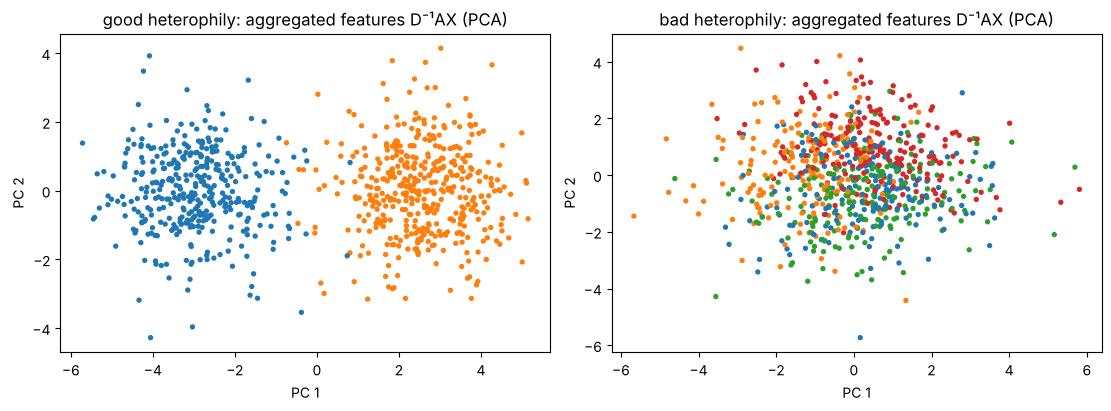

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, kind in zip(axes, ('good', 'bad')):
    A_s, X_s, y_s = synthetic_heterophily(kind)
    agg = (row_norm(A_s) @ X_s).cpu().numpy()
    W = np.linalg.svd(agg - agg.mean(0), full_matrices=False)[2][:2].T     # top-2 principal directions
    P = (agg - agg.mean(0)) @ W
    ax.scatter(P[:, 0], P[:, 1], c=y_s.cpu().numpy(), cmap='tab10', vmin=0, vmax=9, s=8)
    ax.set(title=f'{kind} heterophily: aggregated features D⁻¹AX (PCA)', xlabel='PC 1', ylabel='PC 2')
plt.show()

Explanation. Both graphs have $h_{edge}=0$ and a negative $h_{adj}$ (−1 for the bipartite graph), yet:

* In the bipartite graph every class-0 node aggregates class-1 neighbours and vice versa. All nodes of a class are corrupted in the same way: their aggregated features are noisy samples of the same distribution (the other class' mean), so $D^{-1}AX$ is *more* separable than $X$ (0.98 vs. 0.86: averaging also removes noise). $LI = 1$: a neighbour's label determines the node's label.
* In the random-heterophily graph every class sees a similar mixture of the other three classes, so the aggregated features of different classes overlap and aggregation hurts (0.53 vs. 0.69). $LI = 0.21$: a neighbour's label only says which class the node is not.

GCN-like aggregation learns similar embeddings for same-label nodes iff they have similar neighbourhood label distributions, whatever the value of $h_{edge}$. That is what good (benign) and bad (malignant) heterophily mean.